### Кейс 7 Прогнозирование энергопотребления бытовой техники

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("energydata_complete.csv")

####  Загрузка и первичный осмотр

In [2]:
for col in df.columns:
    print(col)
    #Наименование столбцов

date
Appliances
lights
T1
RH_1
T2
RH_2
T3
RH_3
T4
RH_4
T5
RH_5
T6
RH_6
T7
RH_7
T8
RH_8
T9
RH_9
T_out
Press_mm_hg
RH_out
Windspeed
Visibility
Tdewpoint
rv1
rv2


In [3]:
descriptions = {
    'date': 'Дата и время записи',
    'Appliances': 'Потребление энергии бытовой техники(Вт)',
    'lights': 'Потребление энергии осветительных приборов(Вт)',
    'T1': 'Температура на кухне,°C',
    'RH_1': 'Влажность на кухне, %',
    'T2': 'Температура в гостиной,°C',
    'RH_2': 'Влажность в гостиной, %',
    'T3': 'Температура в прачечной,°C',
    'RH_3': 'Влажность в прачечной, %',
    'T4': 'Температура в кабинете,°C',
    'RH_4': 'Влажность в кабинете, %',
    'T5': 'Температура в ванной комнате,°C',
    'RH_5': 'Влажность в ванной комнате, %',
    'T6': 'Температура снаружи здания (северная сторона),°C',
    'RH_6': 'Влажность снаружи здания (северная сторона), %',
    'T7': 'Температура в гладильной комнате,°C',
    'RH_7': 'Влажность в гладильной комнате, %',
    'T8': 'Температура во второй комнате подростка,°C',
    'RH_8': 'Влажность во второй комнате подростка, %',
    'T9': 'Температура в комнате родителей,°C',
    'RH_9': 'Влажность в комнате родителей, %',
    'T_out': 'Температура на улице (с метеостанции в Шивре),°C',
    'Press_mm_hg': 'Давление (с метеостанции в Шивре), в мм рт. ст',
    'RH_out': 'Влажность на улице (с метеостанции в Шивре),  %',
    'Windspeed': 'Скорость ветра (с метеостанции в Шивре), м/с ',
    'Visibility': 'Видимость (с метеостанции в Шивре), км',
    'Tdewpoint': 'Точка росы (с метеостанции в Шивре),°C',
    'rv1': 'Случайная переменная 1, безразмерная ',
    'rv2': 'Случайная переменная 2, безразмерная '
    

}

table_data =[]
for col in df.columns:
    table_data.append({
        "Столбец": col,
        "Тип": df[col].dtype,
        "Описание": descriptions.get(col, "Нет описания")
    })

descriptions_df =pd.DataFrame(table_data)
display(descriptions_df)

,Столбец,Тип,Описание
0,date,str,Дата и время записи
1,Appliances,int64,Потребление энергии бытовой техники(Вт)
2,lights,int64,Потребление энергии осветительных приборов(Вт)
3,T1,float64,"Температура на кухне,°C"
4,RH_1,float64,"Влажность на кухне, %"
5,T2,float64,"Температура в гостиной,°C"
6,RH_2,float64,"Влажность в гостиной, %"
7,T3,float64,"Температура в прачечной,°C"
8,RH_3,float64,"Влажность в прачечной, %"
9,T4,float64,"Температура в кабинете,°C"


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

Пропущенных значений(Nan) нет

Общее кол-во строк 19735

Столбцов 29

Необходимо преобразовать тип столбца date

In [5]:
df['date'] = pd.to_datetime(df['date'])

In [6]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,19735,2016-03-20 05:29:59.999999,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
Appliances,19735.0,97.694958,10.0,50.0,60.0,100.0,1080.0,102.524891
lights,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884


#### Одномерный анализ.

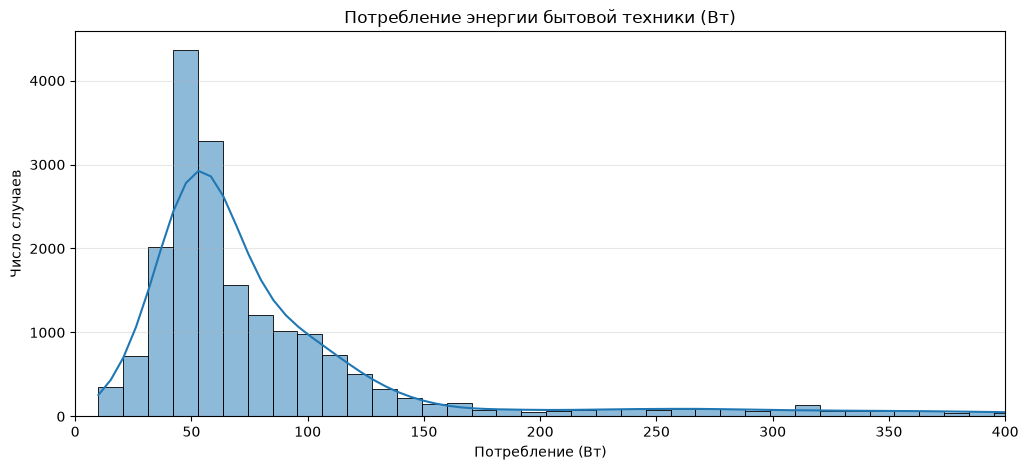

In [7]:

plt.figure(figsize=(12, 5))
sns.histplot(df['Appliances'], bins=100, kde=True)
plt.xlim(0, 400)
plt.title('Потребление энергии бытовой техники (Вт)')
plt.xlabel('Потребление (Вт)')
plt.ylabel('Число случаев')
plt.grid(axis='y', alpha=0.3)
plt.show()

Имеется правосторонняя асимметрия. Значение выше 150 Вт встречается реже, представляет собой пиковые нагрузки.На графике имеется 'длинный хвост', который тянется в право до 1080 Вт в исходных данных, что потверждает наличие выбросов

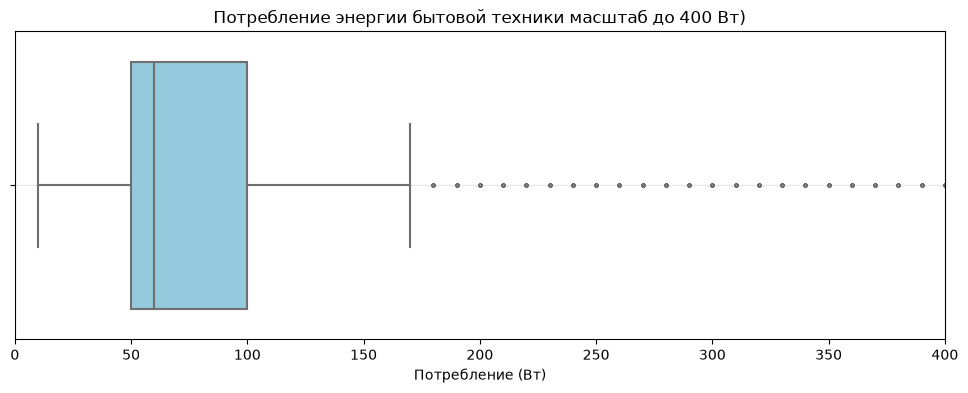

In [8]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=df['Appliances'], color='skyblue', fliersize=2, linewidth=1.5)

plt.xlim(0, 400) 

plt.title('Потребление энергии бытовой техники масштаб до 400 Вт)')
plt.xlabel('Потребление (Вт)')
plt.grid(axis='y', alpha=0.3)
plt.show()

Анализ Boxplot потвердил наличие выбросов(Ящик с усами узкий и прижат влево, данные сильно скошены), которые не являются ошибками измерения, а предоставляют собой скачки назгрузки бытовых приборов.

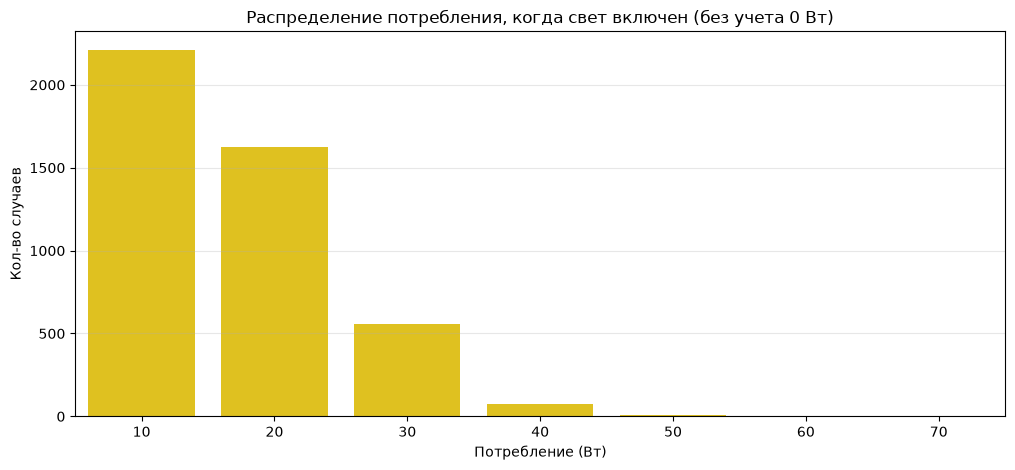

In [9]:

lights_on = df[df['lights'] > 0]

plt.figure(figsize=(12, 5))


sns.countplot(x='lights', data=lights_on, color='gold')


plt.title('Распределение потребления, когда свет включен (без учета 0 Вт)')
plt.xlabel('Потребление (Вт)')
plt.ylabel('Кол-во случаев')
plt.grid(axis='y', alpha=0.3)

plt.show()

Свет - это слабая бинарная переменная. Имеет строго дискретный характер и ограничен физическим пределом освещения(макс 70ВТ). При анализе включенного света видны пики на 10 и 20 вт. Поскольку целевой переменной является потребление бытовой техники, абсолютные значения мощности света несопоставимы с ней. Однако, этот признак может выступать ка бинарный маркер активности(свет включен=люди не спят и могут использовать технику)

####  Многомерный анализ

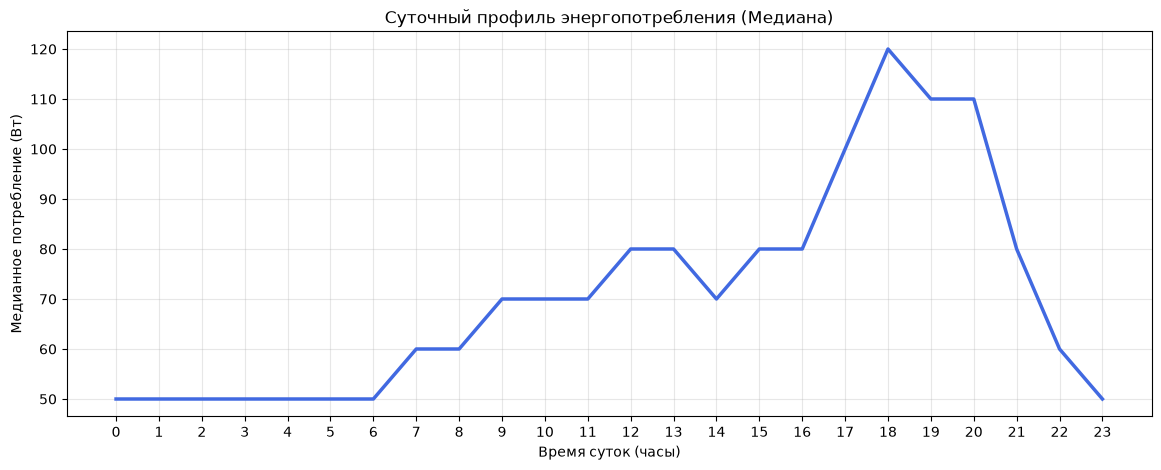

In [10]:
df['hour'] = df['date'].dt.hour

plt.figure(figsize=(14, 5))

sns.lineplot(x='hour', y='Appliances', data=df, estimator='median', errorbar=None, color='royalblue', linewidth=2.5)

plt.title('Суточный профиль энергопотребления (Медиана)')
plt.xlabel('Время суток (часы)')
plt.ylabel('Медианное потребление (Вт)')
plt.xticks(range(0, 24)) 
plt.grid(True, alpha=0.3)
plt.show()

Присутствует четкая цикличность потребления. Потребление энергии бытовыми приборами напрямую завсит от распорядка дня жильцов. Ночью работает только базовая техника, поэтому график на минимуме. По мере пробуждения жильцов график постепенно растет. Максимальная нагрузка приходится на вечер (пик в 18:00), когда все семья дома и активно пользуется приборами. Признак "час суток" будет одним из ключевых, так как лучше всего обьясняет поведение людей

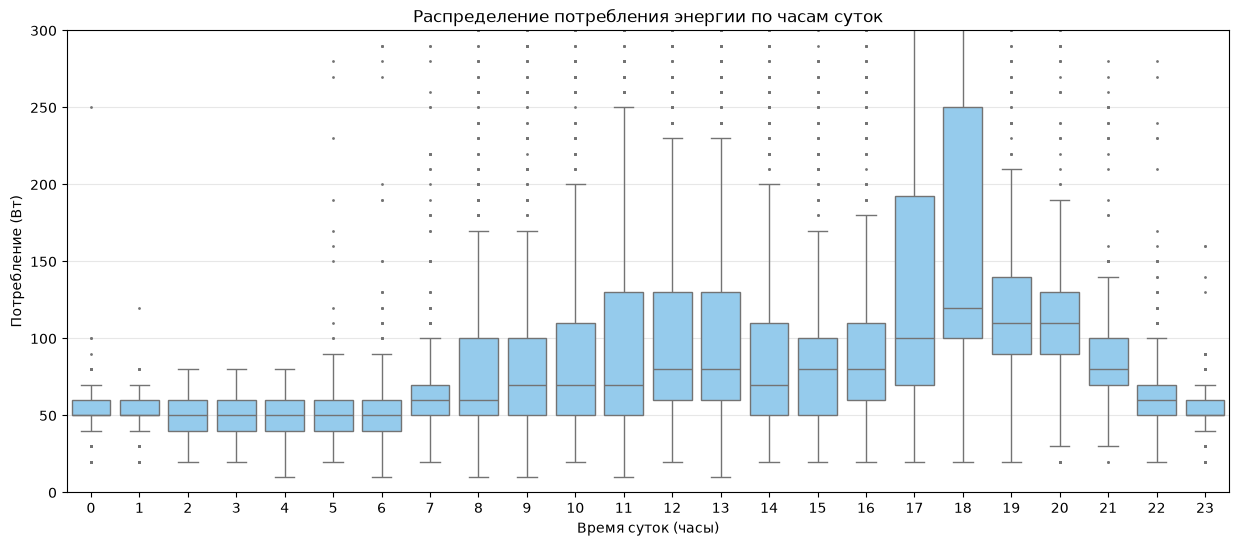

In [11]:
plt.figure(figsize=(15, 6))


sns.boxplot(x='hour', y='Appliances', data=df, color='lightskyblue', fliersize=1, linewidth=1)

plt.title('Распределение потребления энергии по часам суток')
plt.xlabel('Время суток (часы)')
plt.ylabel('Потребление (Вт)')
plt.ylim(0, 300)
plt.grid(axis='y', alpha=0.3)
plt.show()


Распределение выбросов по времени крайне неравномерно. Ночью практически отсутствуют, но вечером имеют максимальное количество — в вечерний час пик (18:00). Данные выбросы являются реальными пиковыми нагрузками (включение мощных приборов), а не ошибками измерений, поэтому их нельзя удалять. Наличие большого количества высоких выбросов в вечернее время требует использования метрики MAE (средняя абсолютная ошибка) вместо MSE, которая слишком сильно штрафует за большие отклонения. Для модели потребуется выбрать алгоритм, устойчивый к выбросам 

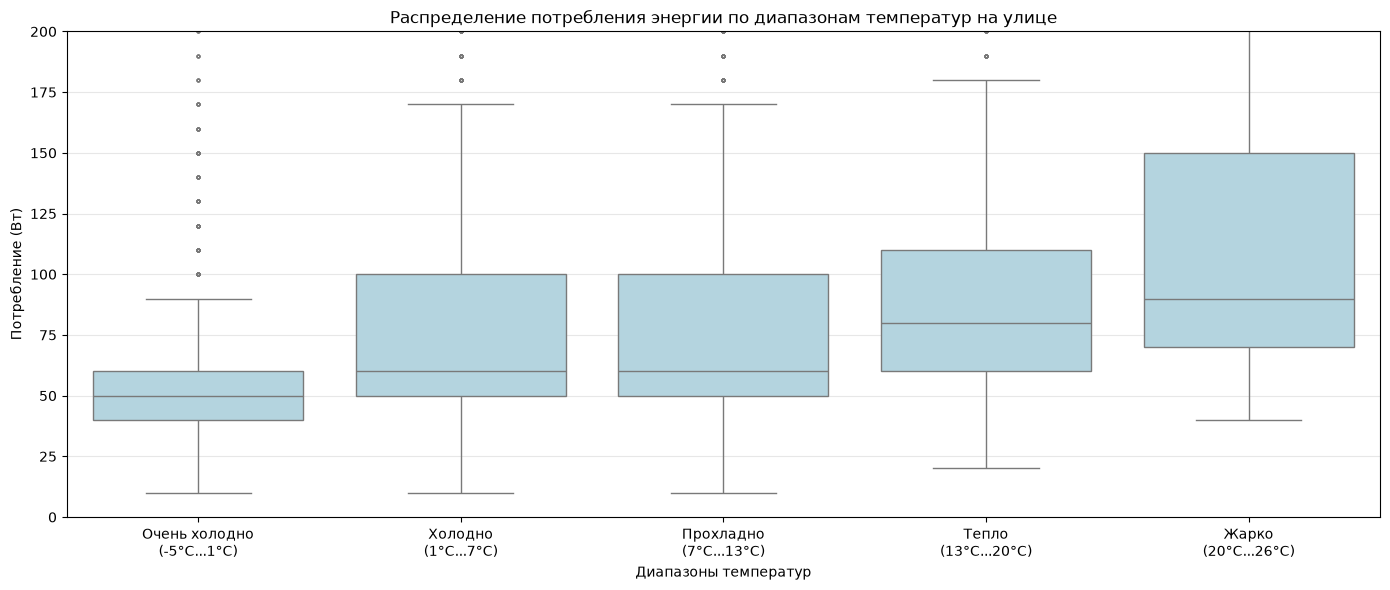

In [12]:
df['month'] = df['date'].dt.month


temp_labels = [
    'Очень холодно\n(-5°C...1°C)', 
    'Холодно\n(1°C...7°C)', 
    'Прохладно\n(7°C...13°C)', 
    'Тепло\n(13°C...20°C)', 
    'Жарко\n(20°C...26°C)'
]


df['temp_range'] = pd.cut(df['T_out'], bins=5, labels=temp_labels)

plt.figure(figsize=(14, 6))


sns.boxplot(
    data=df, 
    x='temp_range', 
    y='Appliances', 
    color='lightblue', 
    showfliers=True,
    fliersize=2 
)

plt.title('Распределение потребления энергии по диапазонам температур на улице')
plt.xlabel('Диапазоны температур') 
plt.ylabel('Потребление (Вт)')
plt.ylim(0, 200) 
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Для анализа влияние погоды разбили непрерывную температуру на 5 интервалов. Деление по месяцам было бы некорректным(связано со скачками температуры внутри месяца), это бы смешало эффект погоды с календарным фактором.

На графике мы видим пряммую зависимость(С ростом температуры медианное потребление растет). В теплые периоды «ящик» становится значительно шире. Это значит, что в жару люди используют технику более хаотично и непредсказуемо, чем в холод. 

В категории «Очень холодно» нет аномально высоких пиков. Это доказывает, что электроэнергия не используется для основного обогрева дома.

Анализ доказал, что зависимость между температурой и потреблением нелинейная. Линейная регрессия тут не справится, можно попробовать древовидные модели. из-за огромного разброса данных в категории Жарко, модель будет ошибаться там чаще, чем в холода. Мы должны учитывать это при оценке качества

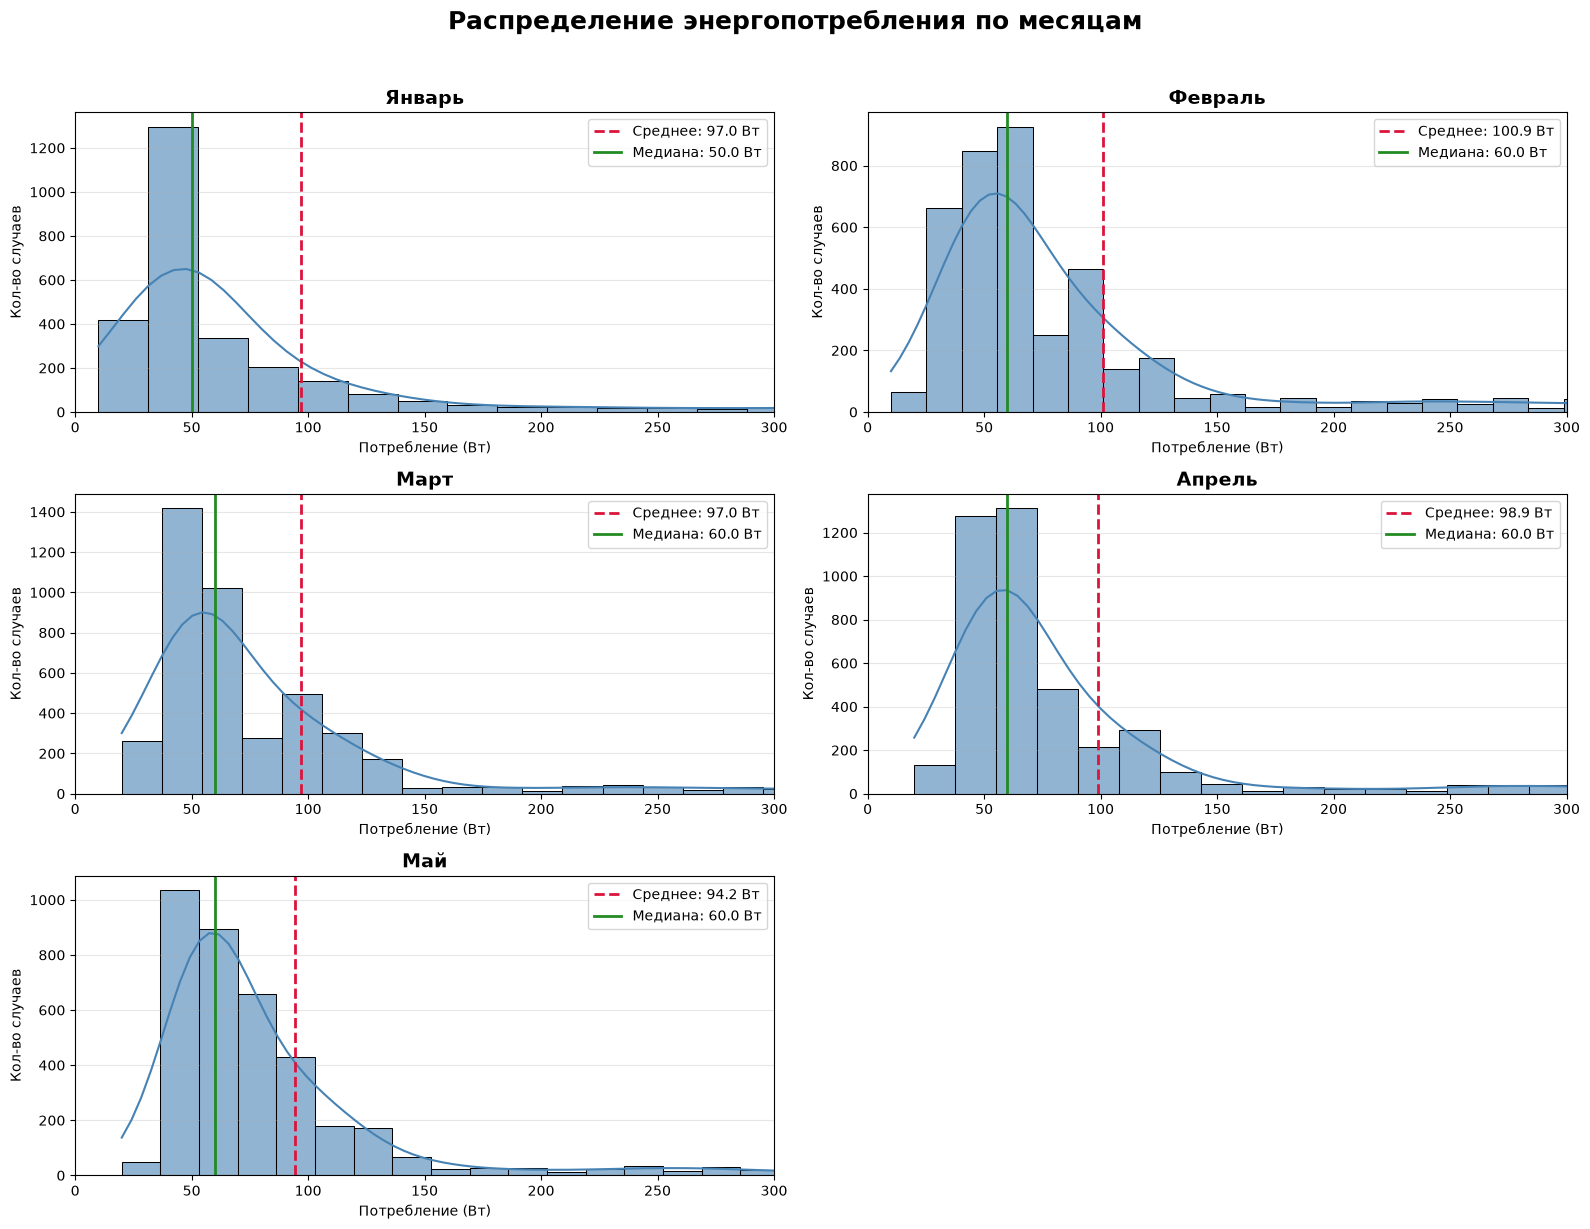

In [13]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(16, 12))
axes = axes.flatten()

months = sorted(df['month'].unique())
month_names = {1: 'Январь', 2: 'Февраль', 3: 'Март', 4: 'Апрель', 5: 'Май'}

for i, month in enumerate(months):
    ax = axes[i]
    data = df[df['month'] == month]['Appliances']
    
    
    sns.histplot(data, bins=50, kde=True, ax=ax, color='steelblue', alpha=0.6)
    
    
    mean_val = data.mean()
    median_val = data.median()
    
    ax.axvline(mean_val, color='crimson', linestyle='--', linewidth=2, label=f'Среднее: {mean_val:.1f} Вт')
    ax.axvline(median_val, color='forestgreen', linestyle='-', linewidth=2, label=f'Медиана: {median_val:.1f} Вт')
    
    ax.set_title(f'{month_names.get(month, month)}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Потребление (Вт)')
    ax.set_ylabel('Кол-во случаев')
    ax.set_xlim(0, 300) 
    ax.legend(loc='upper right', fontsize=10)
    ax.grid(axis='y', alpha=0.3)

# Удаляем лишнюю 6-ю ячейку
fig.delaxes(axes[5])

fig.suptitle('Распределение энергопотребления по месяцам', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Распредение энергии по месяцам показывает, что для дальнейшей работы мы не можем использовать среднее арифмитическое. Красная линия(среднее) везде сильно правее зеленой (медианы). Из-за мощных приборов среднее значение искажено. Модель должна быть устойчива к таким искажениям(желательно использовать MAE). 

Признак "месяц" полезен, так как помогает модели понять, что в феврале вероятность высоких нагрузок выше, чем в мае

#### Анализ взаимосвязей признаков

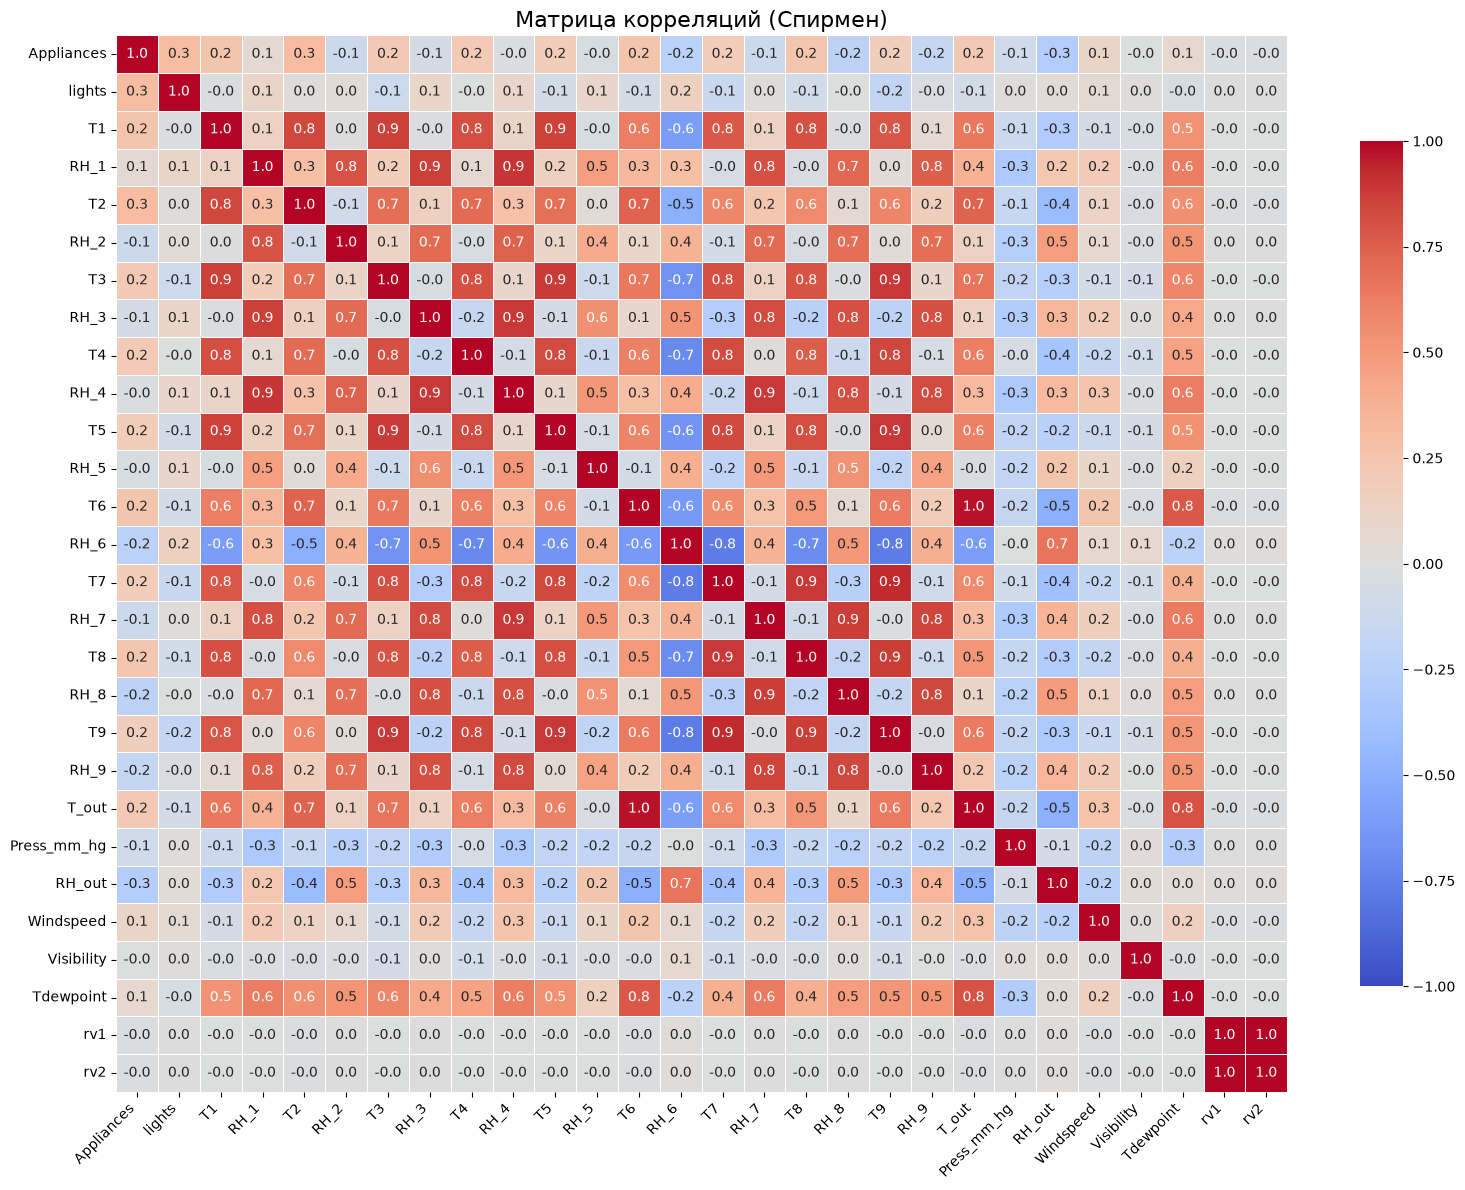

In [14]:
plt.figure(figsize=(16, 12))


corr_matrix = df.select_dtypes(include=['float64', 'int64']).corr(method='spearman')


sns.heatmap(
    corr_matrix, 
    annot=True,          
    fmt='.1f',           
    cmap='coolwarm',     
    vmin=-1, vmax=1,     
    center=0,
    linewidths=.5,
    cbar_kws={"shrink": .8} 
)

plt.title('Матрица корреляций (Спирмен)', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

1.  Выбран Спирмен, так как он устойчив к экстремальным выбросам (до 1080 Вт), которые присутствуют в целевой переменной. Пирсон в таких условиях даст искаженный результат.

2. Прямых и сильных линейных связей нет. Максимальные показатели (по модулю) демонстрируют два признака: свет (lights) и влажность на улице (RH_out) — оба имеют коэффициент 0.3 (свет — прямая связь, влажность — обратная). Связь с температурой на улице (T_out) слабее (-0.2). Это доказывает, что потребление энергии зависит не от одной переменной, а от сложного комплекса нелинейных факторов (времени суток, привычек).

3. На графике четко видны красные блоки между датчиками T1-T9 и RH_1-RH_9 (корреляция 0.8–0.9). Если оставить их все, модель будет переобучена. На этапе Preprocessing мы оставим только по одному репрезентативному датчику (например, T1 и RH_1 для кухни), а остальные удалим.

4. rv1 и rv2 имеют корреляцию 0 со всеми признаками и 1.0 друг с другом. Это искусственный шум, подлежащий удалению.

Удаляем rv1, rv2 и дублирующие датчики. Оставляем lights, T_out, RH_out, T1 и RH_1. Так как связи нелинейные и слабые, используем алгоритмы на основе деревьев, а не линейную регрессию.